# KL divergence and variational inference: companion notebook

ES 667 · Deep Learning · IIT Gandhinagar. Run it alongside the slides: each section says which slides it belongs to.

It follows the PML course notebook `variational-inference.ipynb` (Lectures 23 and 24), with the same examples and
variable names, and needs only `torch`, `numpy` and `matplotlib` (the Pyro cell is optional). Small helpers for plots,
animations and the training loop live in `vi_utils.py`; the lines that carry the ideas are written out here.

**Goals** (from the PML notebook)

- **G1** Given distributions $p$ and $q$, measure how different they are: the KL divergence.
- **G2** Keep $p$ fixed and find the parameters of $q$ that make it as close as possible to $p$.
- **G3** Measure the KL between distributions of different families (a mixture of Gaussians and a Gaussian).
- **G4** Optimise $q$ against such a target: Monte Carlo plus the reparameterisation trick.
- **G5** How good are Monte Carlo estimates of the KL?
- **G6** Variational inference for real posteriors: the coin toss and linear regression.

In [1]:
import inspect
import math

import matplotlib.pyplot as plt
import torch

import vi_utils as vu
from vi_utils import dist

vu.style()
torch.manual_seed(0);

## N1 · Bayes' rule, the evidence, and why it is hard (slides 1.2–1.9)

**Steve is meek and orderly. Librarian or farmer?** (PML Lecture 2.) One librarian for every 20 farmers; the description
fits 40% of librarians and 10% of farmers.

In [2]:
prior = {"librarian": 1 / 21, "farmer": 20 / 21}
likelihood = {"librarian": 0.4, "farmer": 0.1}          # P(meek and orderly | job)

evidence = sum(prior[j] * likelihood[j] for j in prior)  # P(description): add up over every possibility
posterior = {j: prior[j] * likelihood[j] / evidence for j in prior}
print(f"evidence = {evidence:.4f}")
print({j: round(v, 3) for j, v in posterior.items()})

evidence = 0.1143
{'librarian': 0.167, 'farmer': 0.833}


**Bayes' rule for ML.** $\theta$ is what we want to learn, $D$ is what we saw:
$$p(\theta\mid D) = \frac{p(D\mid\theta)\,p(\theta)}{p(D)}, \qquad p(D) = \int p(D\mid\theta)\,p(\theta)\,d\theta .$$

**The coin** from the PML notebook: $\theta = P(\text{heads})$, prior $\mathrm{Beta}(5, 3)$, 17 heads in 30 tosses.

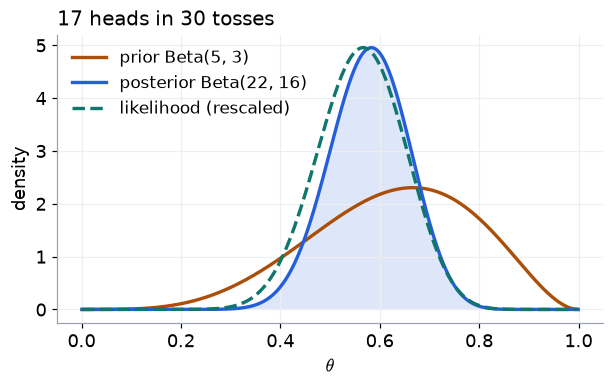

In [3]:
coin = vu.Coin(heads=17, tails=13, a=5, b=3)
theta = vu.grid(0.001, 0.999)

fig, ax = plt.subplots()
vu.plot_dists({"prior Beta(5, 3)": coin.prior, "posterior Beta(22, 16)": coin.posterior}, theta, ax=ax,
              colors={"prior Beta(5, 3)": vu.COLORS["prior"], "posterior Beta(22, 16)": vu.COLORS["post"]},
              fill=["posterior Beta(22, 16)"])
lik = (coin.log_likelihood(theta) - coin.log_likelihood(theta).max()).exp()
ax.plot(theta, lik * vu.density(coin.posterior, theta).max(), color=vu.COLORS["lik"], ls="--", label="likelihood (rescaled)")
ax.legend(loc="upper left")
ax.set_title("17 heads in 30 tosses", loc="left");

**The evidence for the coin has a formula**, because the Beta prior is conjugate to the Bernoulli likelihood:
$p(D) = B(22, 16) / B(5, 3)$. On a 1-D grid we can check it.

In [4]:
print("log p(D), formula:", round(coin.log_evidence, 3))
print("log p(D), 1-D grid:", round(vu.evidence_grid(coin.log_joint, 1e-6, 1 - 1e-6), 3))

log p(D), formula: -21.397
log p(D), 1-D grid: -21.397


**Linear regression also has a formula** (PML Sampling-1, `mc-linreg-evidence.ipynb`):
$p(\mathcal{Y}\mid\mathcal{X}) = \mathcal{N}(\mathbf{y}\mid X\mathbf{m}_0,\ X S_0 X^\top + \sigma^2 I)$.
What if we estimated it by sampling $\theta$ from the prior, $p(D) \approx \frac1N\sum_i p(D\mid\theta_i)$?

In [5]:
torch.manual_seed(42)
x = torch.linspace(-1, 1, 100)
y = 1.5 + 0.5 * x + 0.2 * torch.randn_like(x)            # true theta = (1.5, 0.5), noise 0.2
linreg = vu.LinReg(x, y, noise_sd=0.2, prior_sd=1.0)    # prior theta ~ N(0, I)

log_ev_mc, ll = vu.evidence_mc(linreg.prior, linreg.log_likelihood, n=15_000)
print("log p(D), closed form         :", round(linreg.log_evidence(), 2))
print("log p(D), 15,000 prior draws  :", round(log_ev_mc, 2))
w = torch.softmax(ll, 0)                                  # each draw's share of the average
print(f"the best 10 of 15,000 draws carry {w.topk(10).values.sum():.0%} of the estimate")

log p(D), closed form         : 12.35
log p(D), 15,000 prior draws  : 12.22
the best 10 of 15,000 draws carry 95% of the estimate


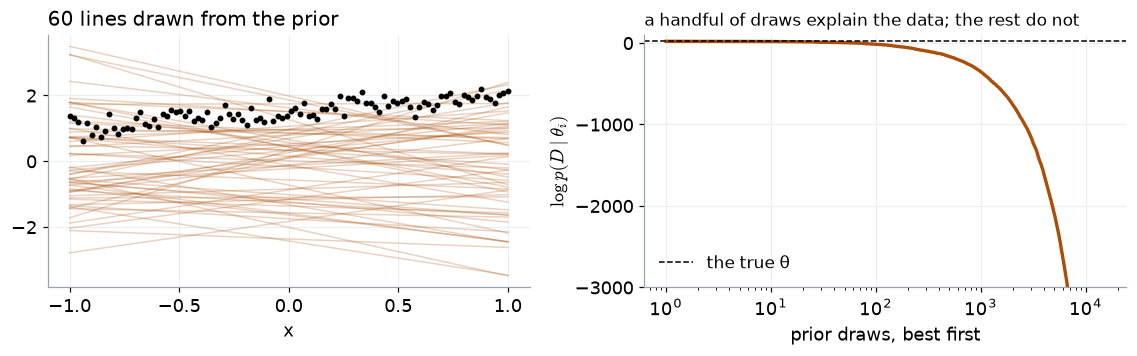

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.4))
for t in linreg.prior.sample((60,)):
    a1.plot(x, t[0] + t[1] * x, color=vu.COLORS["prior"], alpha=0.25, lw=1)
a1.scatter(x, y, s=8, color="k", zorder=3)
a1.set_title("60 lines drawn from the prior", loc="left")
a1.set_xlabel("x")
ll_sorted = ll.sort(descending=True).values
a2.plot(torch.arange(1, len(ll) + 1), ll_sorted, color=vu.COLORS["prior"])
a2.axhline(linreg.log_likelihood(torch.tensor([1.5, 0.5])).item(), color="k", ls="--", lw=1, label="the true θ")
a2.set_xscale("log")
a2.set_ylim(-3000, 100)
a2.set_xlabel("prior draws, best first")
a2.set_ylabel(r"$\log p(D\mid\theta_i)$")
a2.legend(loc="lower left")
a2.set_title("a handful of draws explain the data; the rest do not", loc="left", fontsize=11)
fig.tight_layout();

**When there is no formula at all** (PML Lecture 2, p. 77; the Laplace notebook): put a Normal prior on the coin's logit,
$\theta = \mathrm{sigmoid}(w)$, $w \sim \mathcal{N}(0, 1)$. Now $\int \mathcal{N}(w; 0, 1)\,\mathrm{sigmoid}(w)^{17}(1-\mathrm{sigmoid}(w))^{13}\,dw$
has no closed form. In 1-D a grid or prior sampling still works; with millions of parameters (a neural network) neither does.

In [7]:
lcoin = vu.LogitCoin(heads=17, tails=13, mu=0.0, sigma=1.0)
print("log p(D), 1-D grid           :", round(vu.evidence_grid(lcoin.log_joint, -10, 10), 3))
print("log p(D), 100,000 prior draws:", round(vu.evidence_mc(lcoin.prior, lcoin.log_likelihood, n=100_000)[0], 3))

log p(D), 1-D grid           : -21.616
log p(D), 100,000 prior draws: -21.618


**Three ways around it, on one hard shape** (slide 1.9): a mixture of two Gaussians, the target of the Laplace notebook.
Laplace fits the peak; MCMC wanders over both bumps; VI picks the best member of a simple family.

Laplace: N(-2.00, 1.00) · MCMC acceptance 0.60, mean -0.88 · VI: -0.78, 1.90


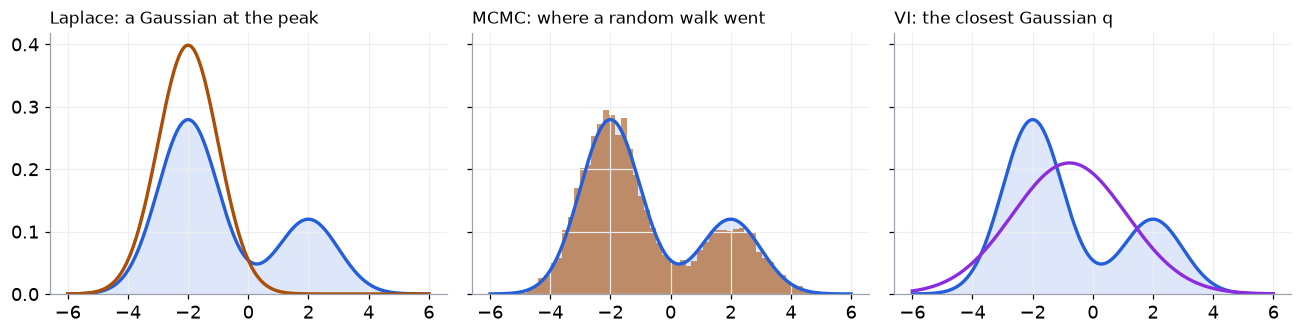

In [8]:
target = vu.mog([0.7, 0.3], [-2.0, 2.0], [1.0, 1.0])
xx = vu.grid(-6, 6)

lap = vu.laplace(target.log_prob, init=0.0)                                  # Gaussian at the mode
samples, acc = vu.metropolis(target.log_prob, init=0.0, steps=20_000, step=2.0)  # random-walk Metropolis
history_vi = vu.fit(vu.TrainableNormal(-0.5, 1.0), lambda q: vu.kl_grid(q, target, vu.grid(-8, 8, 2001)), steps=600)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
titles = ["Laplace: a Gaussian at the peak", "MCMC: where a random walk went", "VI: the closest Gaussian q"]
for ax, t in zip(axs, titles):
    ax.fill_between(xx, 0, vu.density(target, xx), color=vu.COLORS["p"], alpha=0.15, lw=0)
    ax.plot(xx, vu.density(target, xx), color=vu.COLORS["p"])
    ax.set_title(t, loc="left", fontsize=11)
axs[0].plot(xx, vu.density(lap, xx), color=vu.COLORS["prior"])
axs[1].hist(samples, bins=60, density=True, color=vu.COLORS["prior"], alpha=0.6)
axs[2].plot(xx, vu.density(history_vi[-1]["q"], xx), color=vu.COLORS["q"])
fig.tight_layout()
print(f"Laplace: N({lap.loc:.2f}, {lap.scale:.2f}) · MCMC acceptance {acc:.2f}, mean {samples.mean():.2f} · VI: {history_vi[-1]['q'].loc:.2f}, {history_vi[-1]['q'].scale:.2f}")

**The variational idea.** Choose a family $q_\psi(\theta)$ we can sample from and evaluate, and solve
$$\psi^\star = \arg\min_\psi \ \mathrm{KL}\big(q_\psi(\theta)\ \|\ p(\theta\mid D)\big).$$
So first: what is KL?

## N2 · KL divergence (slides 2.1–2.10) · G1

**Build it from a problem** (ritvikmath): a class's favourite fruit in two years. How much did year 2 change, *relative to* year 1?

ratios p/q       : [1.0, 0.25, 4.0]   plain average: 1.75
log ratios       : [0.0, -1.386, 1.386]   (x4 and /4 now cancel)
KL(p || q) = sum p log p/q = 0.416 nats


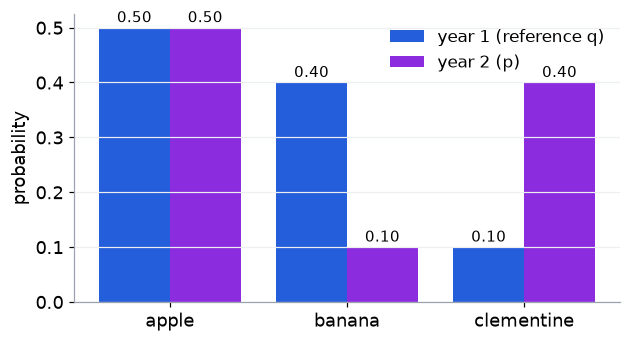

In [9]:
names = ["apple", "banana", "clementine"]
q_year1 = torch.tensor([0.5, 0.4, 0.1])     # the reference
p_year2 = torch.tensor([0.5, 0.1, 0.4])
vu.bars([q_year1, p_year2], ["year 1 (reference q)", "year 2 (p)"], names)

ratio = p_year2 / q_year1
print("ratios p/q       :", [round(v, 2) for v in ratio.tolist()], "  plain average:", round(ratio.mean().item(), 2))
print("log ratios       :", [round(v, 3) for v in ratio.log().tolist()], "  (x4 and /4 now cancel)")
print("KL(p || q) = sum p log p/q =", round((p_year2 * ratio.log()).sum().item(), 3), "nats")

**The same number in bits** (Jia-Bin Huang; PML information-theory lecture): surprise $= \log_2 1/p$; entropy is the average
surprise, the shortest average code; cross-entropy is the average code length when the code was built for the wrong distribution.

In [10]:
H = lambda p: -(p * p.log2()).sum()
CE = lambda p, q: -(p * q.log2()).sum()

weather = torch.tensor([0.50, 0.25, 0.25])     # sunny, cloudy, rainy: codes 0, 10, 11
wrong = torch.tensor([0.25, 0.50, 0.25])       # the forecast our code was built for: codes 10, 0, 11
print(f"entropy {H(weather):.2f} bits · cross-entropy {CE(weather, wrong):.2f} bits · KL = extra {CE(weather, wrong) - H(weather):.2f} bits")

entropy 1.50 bits · cross-entropy 1.75 bits · KL = extra 0.25 bits


**A coin, both ways.** KL is not symmetric. And $e^{n\,\mathrm{KL}}$ is how much likelier the right coin becomes after $n$ tosses.

KL(0.8 coin || fair) = 0.193 · KL(fair || 0.8 coin) = 0.223


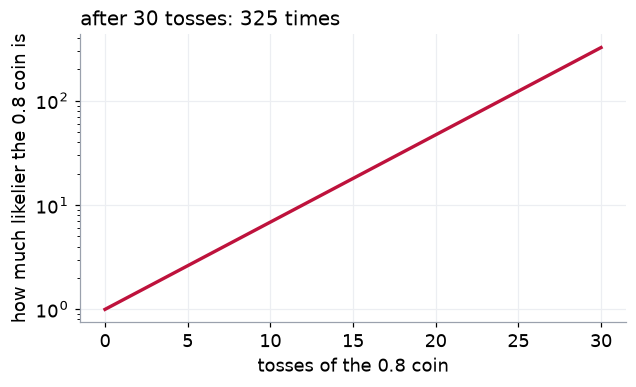

In [11]:
fair, biased = dist.Bernoulli(0.5), dist.Bernoulli(0.8)
kl_bf = dist.kl_divergence(biased, fair)
print(f"KL(0.8 coin || fair) = {kl_bf:.3f} · KL(fair || 0.8 coin) = {dist.kl_divergence(fair, biased):.3f}")

n = torch.arange(0, 31)
plt.semilogy(n, torch.exp(n * kl_bf), color=vu.COLORS["kl"])
plt.xlabel("tosses of the 0.8 coin")
plt.ylabel("how much likelier the 0.8 coin is")
plt.title(f"after 30 tosses: {math.exp(30 * kl_bf):.0f} times", loc="left");

**G1: which $q$ is closer to $p$?** The PML notebook's example: $p = \mathcal{N}(1, 4)$, $q_1 = \mathcal{N}(0, 2)$, $q_2 = \mathcal{N}(1, 3)$ (location, scale).
Vote first, then compute $\mathrm{KL}(q\,\|\,p)$.

KL(q1 || p) = 0.35   KL(q2 || p) = 0.07


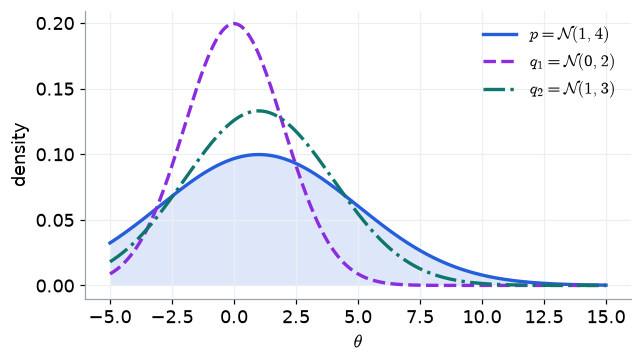

In [12]:
p = dist.Normal(1., 4.)
q1, q2 = dist.Normal(0., 2.), dist.Normal(1., 3.)
z_values = vu.grid(-5, 15)
vu.plot_dists({r"$p=\mathcal{N}(1, 4)$": p, r"$q_1=\mathcal{N}(0, 2)$": q1, r"$q_2=\mathcal{N}(1, 3)$": q2}, z_values,
              fill=[r"$p=\mathcal{N}(1, 4)$"], styles={r"$q_1=\mathcal{N}(0, 2)$": "--", r"$q_2=\mathcal{N}(1, 3)$": "-."})
print(f"KL(q1 || p) = {dist.kl_divergence(q1, p):.2f}   KL(q2 || p) = {dist.kl_divergence(q2, p):.2f}")

**Exercise (slide 2.8).** Derive $\mathrm{KL}\big(\mathcal{N}(\mu_q,\sigma_q^2)\,\|\,\mathcal{N}(\mu_p,\sigma_p^2)\big)$: write it as an
expectation under $q$, expand the logs, and use $\mathbb{E}[\theta] = \mu_q$, $\mathbb{E}[\theta^2] = \sigma_q^2 + \mu_q^2$. Then compare with torch.

In [13]:
def kl_normal(mq, sq, mp, sp):
    # the answer: 1/2 [ log(sp^2 / sq^2) - 1 + ((mq - mp)^2 + sq^2) / sp^2 ]
    return 0.5 * (math.log(sp**2 / sq**2) - 1 + ((mq - mp) ** 2 + sq**2) / sp**2)

print(round(kl_normal(0, 2, 1, 4), 4), round(kl_normal(1, 3, 1, 4), 4))
import torch.distributions.kl as torch_kl
print(inspect.getsource(torch_kl._kl_normal_normal))

0.3494 0.0689
@register_kl(Normal, Normal)
def _kl_normal_normal(p, q):
    var_ratio = (p.scale / q.scale).pow(2)
    t1 = ((p.loc - q.loc) / q.scale).pow(2)
    return 0.5 * (var_ratio + t1 - 1 - var_ratio.log())



**Forward vs reverse KL** on the mixture from N1. $\mathrm{KL}(p\,\|\,q)$ averages where $p$ has mass, so $q$ must cover everything;
$\mathrm{KL}(q\,\|\,p)$ averages where $q$ has mass, so $q$ avoids the gap and sits on one bump. VI minimises the second.

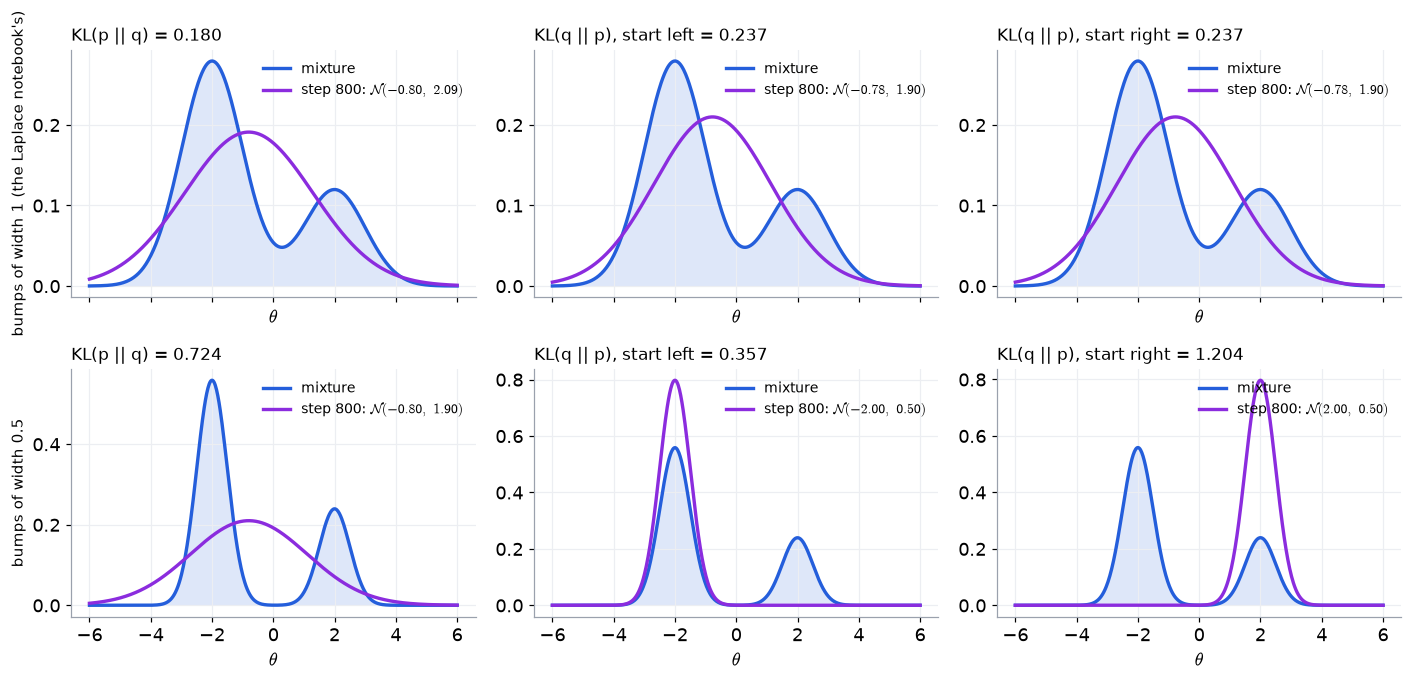

In [14]:
xg = vu.grid(-8, 8, 2001)
narrow = vu.mog([0.7, 0.3], [-2.0, 2.0], [0.5, 0.5])   # the same mixture with narrower bumps

fig, axs = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for row, mix, what in ((axs[0], target, "bumps of width 1 (the Laplace notebook's)"), (axs[1], narrow, "bumps of width 0.5")):
    forward_kl = lambda q, mix=mix: vu.kl_grid(mix, q, xg)    # KL(p || q): averaged where p has mass
    reverse_kl = lambda q, mix=mix: vu.kl_grid(q, mix, xg)    # KL(q || p): averaged where q has mass
    fits = [("KL(p || q)", vu.fit(vu.TrainableNormal(0.5, 0.6), forward_kl, steps=800)),
            ("KL(q || p), start left", vu.fit(vu.TrainableNormal(-0.5, 0.6), reverse_kl, steps=800)),
            ("KL(q || p), start right", vu.fit(vu.TrainableNormal(0.5, 0.6), reverse_kl, steps=800))]
    for ax, (t, h) in zip(row, fits):
        vu.snapshots(h, mix, xx, at=(-1,), ax=ax, target_label="mixture")
        ax.set_title(f"{t} = {h[-1]['loss']:.3f}", loc="left", fontsize=11)
    row[0].set_ylabel(what, fontsize=10)
fig.tight_layout();

## N3 · Optimising $q$ (slides 3.1–3.4) · G2

Keep $p = \mathcal{N}(1, 4)$ fixed and pretend we only know how to evaluate it. First a grid of candidates:

In [15]:
for loc in [0., 1.]:
    for scale in [1., 2., 4.]:
        print(f"q = N({loc:.0f}, {scale:.0f}):  KL(q || p) = {dist.kl_divergence(dist.Normal(loc, scale), p):.3f}")

q = N(0, 1):  KL(q || p) = 0.949
q = N(0, 2):  KL(q || p) = 0.349
q = N(0, 4):  KL(q || p) = 0.031
q = N(1, 1):  KL(q || p) = 0.918
q = N(1, 2):  KL(q || p) = 0.318
q = N(1, 4):  KL(q || p) = 0.000


Then gradient descent. The scale must stay positive, so we learn a raw number and pass it through softplus
(PML notebook: `TrainableNormal`). This is the whole loop that `vu.fit` runs later (it replaces ASTRA's `train_fn`):

In [16]:
q = vu.TrainableNormal(loc=4.0, scale=0.5)
opt = torch.optim.Adam(q.parameters(), lr=0.05)
history = []
for step in range(400):
    loss = dist.kl_divergence(q(), p)          # q() is the current N(loc, softplus(raw_scale))
    history.append(dict(step=step, loss=loss.item(), q=dist.Normal(q.loc.item(), q().scale.item())))
    opt.zero_grad()
    loss.backward()
    opt.step()
q

TrainableNormal(loc=1.00, scale=4.00)

In [17]:
vu.animate_fit(history, target=p, x=z_values, target_label=r"$p=\mathcal{N}(1, 4)$")

**The same in two dimensions** (the notebook's second G2 animation). The target is correlated ($\rho = 0.9$). A full-covariance $q$
can match it; a diagonal (mean-field) $q$ cannot tilt, and minimising $\mathrm{KL}(q\,\|\,p)$ makes it too narrow.

diagonal q's widths: [0.436, 0.436]  (the target's: 1, 1; sqrt(1 - rho^2) = 0.436 )


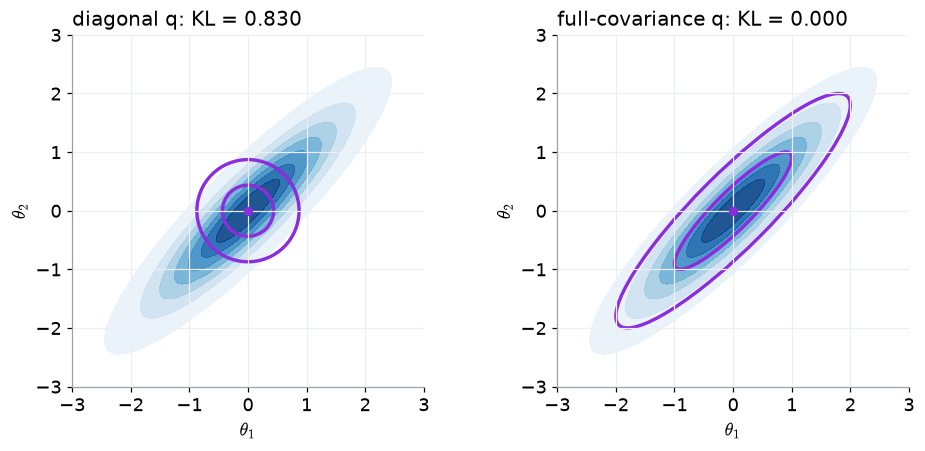

In [18]:
rho = 0.9
p2 = dist.MultivariateNormal(torch.zeros(2), torch.tensor([[1., rho], [rho, 1.]]))
kl2 = lambda q: dist.kl_divergence(q, p2)
h_diag = vu.fit(vu.TrainableGaussian2D((1.5, -1.0), 0.5, full=False), kl2, steps=600)
h_full = vu.fit(vu.TrainableGaussian2D((1.5, -1.0), 0.5, full=True), kl2, steps=600)

fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, h, t in ((axs[0], h_diag, "diagonal q"), (axs[1], h_full, "full-covariance q")):
    vu.contour2d(ax, p2)
    vu.ellipse(ax, h[-1]["q"].loc, h[-1]["q"].covariance_matrix, vu.COLORS["q"])
    ax.set_title(f"{t}: KL = {h[-1]['loss']:.3f}", loc="left")
fig.tight_layout()
print("diagonal q's widths:", [round(v, 3) for v in h_diag[-1]["q"].covariance_matrix.diag().sqrt().tolist()],
      " (the target's: 1, 1; sqrt(1 - rho^2) =", round(math.sqrt(1 - rho**2), 3), ")")

In [19]:
vu.animate_fit_2d(h_diag, p2, title="diagonal q")

## N4 · A target from another family: Monte Carlo (slides 4.1–4.5) · G3, G5

The PML notebook's mixture of Gaussians, and two candidate Gaussians. Which is closer?

NotImplementedError: No KL(p || q) is implemented for p type Normal and q type MixtureSameFamily


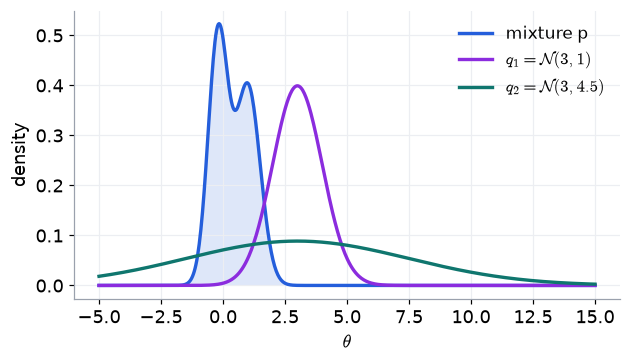

In [20]:
p_s = vu.mog([0.5, 0.5], [-0.2, 1.0], [0.4, 0.5])
q_1, q_2 = dist.Normal(3., 1.), dist.Normal(3., 4.5)
vu.plot_dists({"mixture p": p_s, r"$q_1=\mathcal{N}(3, 1)$": q_1, r"$q_2=\mathcal{N}(3, 4.5)$": q_2}, z_values, fill=["mixture p"])
try:
    dist.kl_divergence(q_1, p_s)
except NotImplementedError as e:
    print("NotImplementedError:", e)

No formula between these two families. But KL is an expectation under $q$, so Monte Carlo:
$\mathrm{KL}(q\,\|\,p) \approx \frac1N \sum_i \big[\log q(\theta_i) - \log p(\theta_i)\big]$, with $\theta_i \sim q$.

In [21]:
torch.manual_seed(0)

def kl_via_sampling(q, p, n_samples=100_000):
    sample_set = q.sample([n_samples])                    # draws from the FIRST argument
    return torch.mean(q.log_prob(sample_set) - p.log_prob(sample_set))

print(f"two Gaussians, exact   : {dist.kl_divergence(q_1, q_2):.4f}")
print(f"two Gaussians, sampling: {kl_via_sampling(q_1, q_2):.4f}")
print(f"mixture: KL(q1 || p) = {kl_via_sampling(q_1, p_s):.2f}   KL(q2 || p) = {kl_via_sampling(q_2, p_s):.2f}")

two Gaussians, exact   : 1.0288
two Gaussians, sampling: 1.0276
mixture: KL(q1 || p) = 9.45   KL(q2 || p) = 45.02


**G5: how good is the estimate?** Unbiased, but the spread shrinks only like $1/\sqrt{N}$.

spread: [0.212, 0.065, 0.021, 0.007]


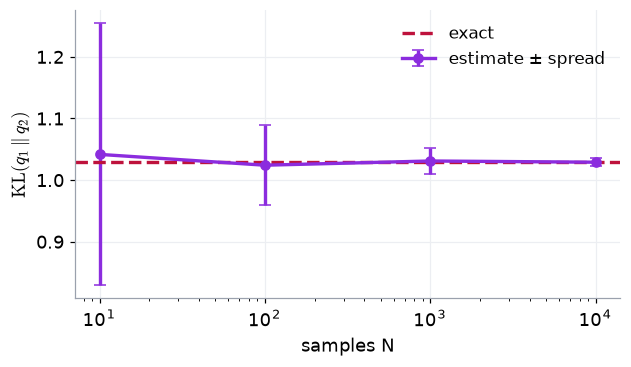

In [22]:
torch.manual_seed(1)
Ns = [10, 100, 1_000, 10_000]
reps = torch.stack([torch.stack([kl_via_sampling(q_1, q_2, n) for _ in range(200)]) for n in Ns])
plt.errorbar(Ns, reps.mean(1), yerr=reps.std(1), fmt="o-", capsize=4, color=vu.COLORS["q"], label="estimate ± spread")
plt.axhline(dist.kl_divergence(q_1, q_2), color=vu.COLORS["kl"], ls="--", label="exact")
plt.xscale("log")
plt.xlabel("samples N")
plt.ylabel(r"$\mathrm{KL}(q_1\,\|\,q_2)$")
plt.legend()
print("spread:", [round(s, 3) for s in reps.std(1).tolist()])

## N5 · Gradients through samples: reparameterisation (slides 5.1–5.6) · G4

Can we now minimise the Monte Carlo KL by gradient descent? The loss is computed from samples, and a sample has no gradient path:

In [23]:
loc = torch.tensor(2.0, requires_grad=True)
scale = torch.tensor(0.5, requires_grad=True)
q = dist.Normal(loc, scale)
s = q.sample()
try:
    s.backward()
except RuntimeError as e:
    print("RuntimeError:", e)

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn


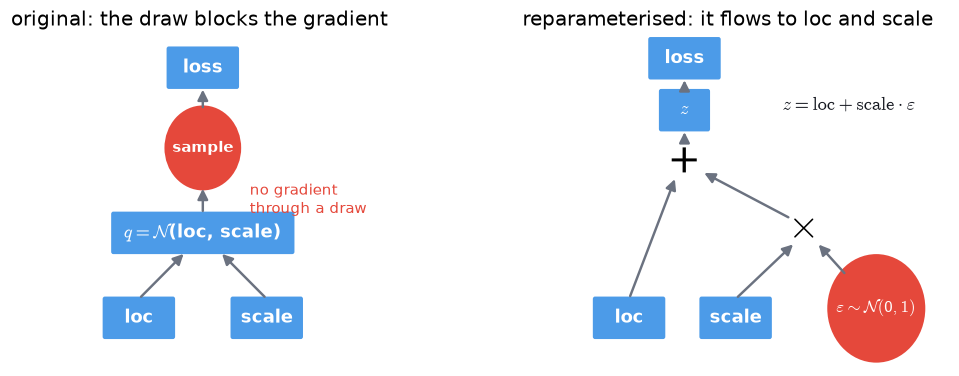

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
vu.graph("sample", ax=axs[0])
axs[0].set_title("original: the draw blocks the gradient", loc="left")
vu.graph("reparam", ax=axs[1])
axs[1].set_title("reparameterised: it flows to loc and scale", loc="left");

**The trick:** draw the randomness from a fixed $\mathcal{N}(0, 1)$, then stretch and shift: $z = \text{loc} + \text{scale}\cdot\varepsilon$.

**Exercise (slide 5.4):** after `z.backward()`, what are `loc.grad` and `scale.grad`?

In [25]:
torch.manual_seed(42)
loc = torch.tensor(2.0, requires_grad=True)
scale = torch.tensor(0.5, requires_grad=True)

eps = dist.Normal(0., 1.).sample()       # randomness that does not depend on loc or scale
z = loc + scale * eps                    # the reparameterised draw
z.backward()
print(f"eps = {eps:.4f}   loc.grad = {loc.grad:.4f}   scale.grad = {scale.grad:.4f}")

eps = 0.3367   loc.grad = 1.0000   scale.grad = 0.3367


`rsample` ("reparameterised sample") does exactly this inside torch. Not every distribution has one.

In [26]:
torch.manual_seed(42)
loc = torch.tensor(2.0, requires_grad=True)
scale = torch.tensor(0.5, requires_grad=True)
z = dist.Normal(loc, scale).rsample()
z.backward()
print(f"loc.grad = {loc.grad:.4f}   scale.grad = {scale.grad:.4f}\n")
print(inspect.getsource(dist.Normal.rsample))
print({d.__name__: d.has_rsample for d in (dist.Normal, dist.Beta, dist.Poisson)})

loc.grad = 1.0000   scale.grad = 0.3367

    def rsample(self, sample_shape: _size = torch.Size()) -> Tensor:
        shape = self._extended_shape(sample_shape)
        eps = _standard_normal(shape, dtype=self.loc.dtype, device=self.loc.device)
        return self.loc + eps * self.scale

{'Normal': True, 'Beta': True, 'Poisson': False}


**G4: fit a Gaussian to the mixture** with the Monte Carlo KL, now differentiable through `rsample`. The notebook's starting point: $\mathcal{N}(6, 0.1)$.

In [27]:
def kl_loss(q, n_samples=5000):
    sample_set = q.rsample([n_samples])                   # reparameterised
    return torch.mean(q.log_prob(sample_set) - p_s.log_prob(sample_set))

q_s = vu.TrainableNormal(loc=6.0, scale=0.1)
history_mog = vu.fit(q_s, kl_loss, steps=1500, lr=0.05)
q_s

TrainableNormal(loc=0.43, scale=0.73)

In [28]:
vu.animate_fit(history_mog, target=p_s, x=vu.grid(-3, 8), target_label="mixture p")

## N6 · The ELBO (slides 6.1–6.6)

Our real target is the posterior, which we do not have. Substituting Bayes' rule into the KL gives
$$\log p(D) = \underbrace{\mathbb{E}_q\big[\log p(D,\theta) - \log q(\theta)\big]}_{\mathrm{ELBO}(q)} + \mathrm{KL}\big(q(\theta)\,\|\,p(\theta\mid D)\big).$$
On the coin we know every term, so we can check it for a few $q$'s.

 q = Beta(10, 10):  ELBO =  -22.020   KL =  0.623   ELBO + KL =  -21.397
 q = Beta(30, 20):  ELBO =  -21.449   KL =  0.051   ELBO + KL =  -21.397
 q = Beta(22, 16):  ELBO =  -21.397   KL =  0.000   ELBO + KL =  -21.397
log p(D) = -21.397


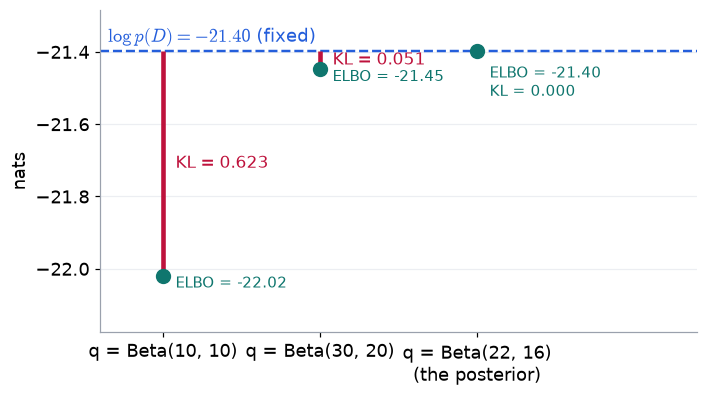

In [29]:
torch.manual_seed(2)

def elbo(log_joint, q, n=200_000):
    theta = q.sample([n]).clamp(1e-6, 1 - 1e-6)
    return (log_joint(theta) - q.log_prob(theta)).mean().item()

candidates = {"q = Beta(10, 10)": dist.Beta(10., 10.), "q = Beta(30, 20)": dist.Beta(30., 20.),
              "q = Beta(22, 16)\n(the posterior)": coin.posterior}
elbos = {}
for label, qc in candidates.items():
    elbos[label] = elbo(coin.log_joint, qc)
    kl = dist.kl_divergence(qc, coin.posterior).item()
    print(f"{label.splitlines()[0]:>17}:  ELBO = {elbos[label]:8.3f}   KL = {kl:6.3f}   ELBO + KL = {elbos[label] + kl:8.3f}")
print(f"log p(D) = {coin.log_evidence:.3f}")
vu.elbo_gaps(coin.log_evidence, elbos);

## N7 · Worked example: the coin (slides 7.1–7.6)

The model as functions (PML notebook): log prior, log likelihood, log joint. The guide is a $\mathrm{Beta}(\alpha, \beta)$: right
support, and it has an `rsample`. We never use the true posterior except to check the answer.

In [30]:
torch.manual_seed(0)

def neg_elbo(log_joint_fn, q, n_mc_samples=100):
    theta = q.rsample([n_mc_samples])                  # draws from q, reparameterised
    log_q_theta = q.log_prob(theta)
    log_joint = log_joint_fn(theta)
    return -(log_joint - log_q_theta).mean()

print("Beta(0.1, 2)  :", round(neg_elbo(coin.log_joint, dist.Beta(0.1, 2.)).item(), 2))
print("true posterior:", round(neg_elbo(coin.log_joint, coin.posterior).item(), 3), "   -log p(D) =", round(-coin.log_evidence, 3))

Beta(0.1, 2)  : 239.38
true posterior: 21.397    -log p(D) = 21.397


In [31]:
q_beta = vu.TrainableBeta(alpha=45.0, beta=45.0)       # the notebook's starting point
history_coin = vu.fit(q_beta, lambda q: neg_elbo(coin.log_joint, q), steps=3000, lr=0.05)
print(q_beta, "   true posterior: Beta(22, 16)")

TrainableBeta(alpha=22.56, beta=16.43)    true posterior: Beta(22, 16)


In [32]:
vu.animate_fit(history_coin, target=coin.posterior, x=vu.grid(0.001, 0.999), loss_name="−ELBO",
               target_label="true posterior Beta(22, 16)")

**The same in Pyro** (optional; `pip install pyro-ppl`): a model, a guide, `Trace_ELBO`, `SVI`.

In [33]:
try:
    import pyro
    import pyro.distributions as pdist
    from pyro.infer import SVI, Trace_ELBO
except ImportError:
    pyro = None
    print("Pyro is not installed here (pip install pyro-ppl). The PML notebook's run ended near Beta(22.9, 16.7).")

if pyro is not None:
    def model(data):
        theta = pyro.sample("theta", pdist.Beta(5.0, 3.0))
        with pyro.plate("data", len(data)):
            pyro.sample("obs", pdist.Bernoulli(theta), obs=data)

    def guide(data):
        alpha_q = pyro.param("alpha_q", torch.tensor(45.0), constraint=dist.constraints.positive)
        beta_q = pyro.param("beta_q", torch.tensor(45.0), constraint=dist.constraints.positive)
        pyro.sample("theta", pdist.Beta(alpha_q, beta_q))

    pyro.clear_param_store()
    svi = SVI(model, guide, pyro.optim.Adam({"lr": 0.05}), loss=Trace_ELBO(num_particles=5))
    for step in range(8001):
        svi.step(coin.data)
    print(pyro.param("alpha_q").item(), pyro.param("beta_q").item())

Pyro is not installed here (pip install pyro-ppl). The PML notebook's run ended near Beta(22.9, 16.7).


## N8 · Worked example: linear regression (slides 8.1–8.3) · G6

The PML notebook's data, $f(x) = 3x + 4$ with noise of scale 5. Prior $\theta \sim \mathcal{N}(0, I)$; here the likelihood uses
the true noise scale, so the exact posterior (Bayesian linear regression has one) can check both $q$'s.

20 points · exact mean [2.55, 3.49], sd [0.745, 0.346] · full q mean [2.53, 3.5], sd [0.718, 0.34]


200 points · exact mean [3.46, 2.8], sd [0.333, 0.121] · full q mean [3.45, 2.8], sd [0.327, 0.12]


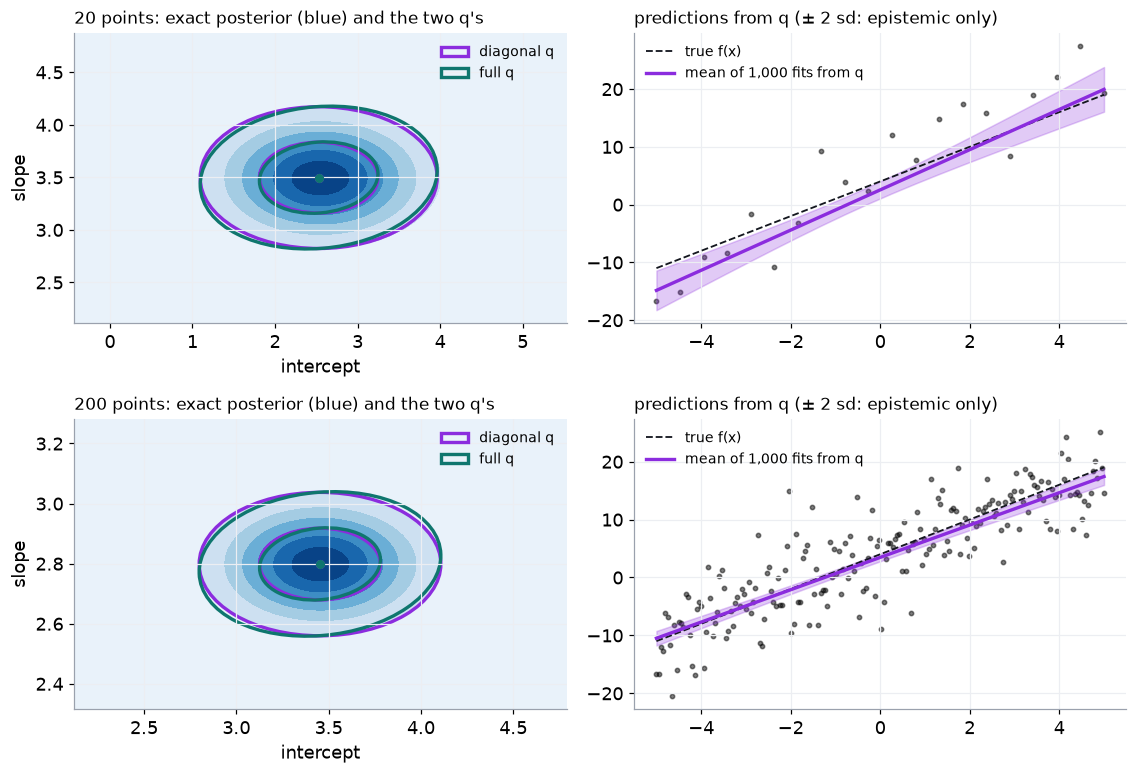

In [34]:
def fit_linreg(n_points, seed=0):
    torch.manual_seed(seed)
    x_lin = torch.linspace(-5, 5, n_points)
    y_lin = 3 * x_lin + 4 + 5 * torch.randn(n_points)
    m = vu.LinReg(x_lin, y_lin, noise_sd=5.0, prior_sd=1.0)

    def neg_elbo_lr(q, n=100):
        theta = q.rsample([n])                          # [n, 2]: (intercept, slope)
        return -(m.log_joint(theta) - q.log_prob(theta)).mean()

    h_d = vu.fit(vu.TrainableGaussian2D((0., 0.), 1.0, full=False), neg_elbo_lr, steps=2000, lr=0.05)
    h_f = vu.fit(vu.TrainableGaussian2D((0., 0.), 1.0, full=True), neg_elbo_lr, steps=2000, lr=0.05)
    return m, x_lin, y_lin, h_d[-1]["q"], h_f[-1]["q"]

fig, axs = plt.subplots(2, 2, figsize=(10.5, 7.2))
for row, n_points in zip(axs, (20, 200)):
    m, x_lin, y_lin, q_diag, q_full = fit_linreg(n_points)
    exact = m.posterior()
    ax = row[0]
    mu, sd = exact.loc, exact.covariance_matrix.diag().sqrt()
    T0, T1 = torch.meshgrid(torch.linspace(mu[0] - 4 * sd[0], mu[0] + 4 * sd[0], 200),
                            torch.linspace(mu[1] - 4 * sd[1], mu[1] + 4 * sd[1], 200), indexing="xy")
    Z = exact.log_prob(torch.stack([T0, T1], -1)).exp()
    ax.contourf(T0, T1, Z / Z.max(), levels=8, cmap="Blues")
    vu.ellipse(ax, q_diag.loc, q_diag.covariance_matrix, vu.COLORS["q"], label="diagonal q")
    vu.ellipse(ax, q_full.loc, q_full.covariance_matrix, vu.COLORS["lik"], label="full q")
    ax.set_xlabel("intercept"); ax.set_ylabel("slope"); ax.legend(loc="upper right", fontsize=9)
    ax.set_title(f"{n_points} points: exact posterior (blue) and the two q's", loc="left", fontsize=11)
    ax = row[1]
    th = q_full.sample([1000])
    preds = th[:, :1] + th[:, 1:] * x_lin
    ax.scatter(x_lin, y_lin, s=8, color="k", alpha=0.5)
    ax.plot(x_lin, 3 * x_lin + 4, color=vu.COLORS["ink"], ls="--", lw=1.2, label="true f(x)")
    ax.fill_between(x_lin, preds.mean(0) - 2 * preds.std(0), preds.mean(0) + 2 * preds.std(0), color=vu.COLORS["q"], alpha=0.25)
    ax.plot(x_lin, preds.mean(0), color=vu.COLORS["q"], label="mean of 1,000 fits from q")
    ax.legend(fontsize=9); ax.set_title("predictions from q (± 2 sd: epistemic only)", loc="left", fontsize=11)
    print(f"{n_points} points · exact mean {[round(v, 2) for v in exact.loc.tolist()]}, sd {[round(v, 3) for v in exact.covariance_matrix.diag().sqrt().tolist()]}"
          f" · full q mean {[round(v, 2) for v in q_full.loc.tolist()]}, sd {[round(v, 3) for v in q_full.covariance_matrix.diag().sqrt().tolist()]}")
fig.tight_layout();

## From $\theta$ to $z$: the VAE

Rename $\theta \to z$ (a code) and $D \to x$ (an image). The prior is $\mathcal{N}(0, I)$, the likelihood $p(x\mid z)$ is the decoder,
and every image has its own posterior, so an encoder predicts $q(z\mid x) = \mathcal{N}(\mu(x), \sigma(x)^2)$. The loss is
$-\mathrm{ELBO} = -\mathbb{E}_q[\log p(x\mid z)] + \mathrm{KL}\big(q(z\mid x)\,\|\,\mathcal{N}(0, I)\big)$: the Gaussian KL of N2,
with $z = \mu + \sigma\varepsilon$ from N5.